# Density estimation on the response-map dataset

Same generator as the regression notebook — *the identical cell* — new question. Before: $p(y \mid \eta,\phi)$, a scalar given a position. Now we want to model the positions themselves, and eventually everything at once:

1. **the acceptance** $p(\eta,\phi)$ — an unconditional 2D density with visible structure (falloff, $\cos 2\phi$ ripple, the prescaled sector) and an **analytic truth**, so for once in density estimation every claim is checkable: exact log-score gap, exact KL, per-point density-ratio maps;
2. **latent-space calibration** — the density-estimation analogue of the PIT histogram;
3. **epistemic uncertainty on a density** — an ensemble of flows;
4. **the joint** $p(y, \eta, \phi)$ — whose slices must reproduce the analytic conditionals the regression notebook fitted directly. This is the bridge: a network emitting a joint/conditional density over data and parameters is what NPE and NLE are.

The "sector" runs at 4% efficiency instead of 0, a density with exact zeros makes maximum likelihood ill-posed (any leaked mass costs infinite NLL) and support mismatches undefined. Prescaled, everything is finite and the sector becomes a hard-but-fair test.



In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from math import erfc

rng = np.random.default_rng(0); torch.manual_seed(0)
plt.rcParams["figure.figsize"] = (7, 3); plt.rcParams["figure.dpi"] = 110
_erfc = np.vectorize(erfc)

# ---------- SHARED GENERATOR (identical cell in the density-estimation notebook) ----------
ETA_MAX, SECTOR, SECTOR_EFF, TAU = 2.5, (0.6, 1.2), 0.04, 0.06

def mu_true(eta, phi):
    crack = -0.06 * np.exp(-0.5 * ((np.abs(eta) - 1.5) / 0.10) ** 2)   # crack rings at |eta|=1.5
    align =  0.012 * np.cos(phi)                                        # cartoon misalignment
    patch = -0.08 * np.exp(-0.5 * (((eta - 0.5) ** 2 + (phi + 2.0) ** 2) / 0.25 ** 2))  # bad supermodule
    return 1.0 + crack + align + patch

def sigma_true(eta):  return 0.02 + 0.03 * (np.abs(eta) / ETA_MAX) ** 2
def ptail_true(eta):  return 0.05 + 0.15 * (np.abs(eta) / ETA_MAX) ** 2

def p_y_cond(y, eta, phi):
    """ANALYTIC p(y|eta,phi): Gaussian core + EMG low-side tail (exp. modified Gaussian)."""
    mu, sig, pt = mu_true(eta, phi), sigma_true(eta), ptail_true(eta)
    lam = 1.0 / TAU
    gauss = np.exp(-0.5 * ((y - mu) / sig) ** 2) / (sig * np.sqrt(2 * np.pi))
    z = ((y - mu) / sig + lam * sig) / np.sqrt(2)
    emg = 0.5 * lam * np.exp(np.clip(lam * (y - mu) + 0.5 * (lam * sig) ** 2, -700, 700)) * _erfc(z)
    return (1 - pt) * gauss + pt * emg

def p_eta_un(eta):    return np.exp(-0.5 * (eta / 1.4) ** 2)
def sector_eff(phi):  return np.where((phi > SECTOR[0]) & (phi < SECTOR[1]), SECTOR_EFF, 1.0)
def p_phi_un(phi):    return (1 + 0.25 * np.cos(2 * phi)) * sector_eff(phi)
_eg = np.linspace(-ETA_MAX, ETA_MAX, 4001); _pg = np.linspace(-np.pi, np.pi, 4001)
Z_ETA = np.trapezoid(p_eta_un(_eg), _eg); Z_PHI = np.trapezoid(p_phi_un(_pg), _pg)

def log_p_pos(eta, phi):
    """ANALYTIC acceptance density p(eta, phi) (separable)."""
    return np.log(p_eta_un(eta) / Z_ETA) + np.log(p_phi_un(phi) / Z_PHI)

def simulate(n, rng):
    eta = np.empty(0)
    while eta.size < n:
        cand = rng.normal(0, 1.4, 2 * n); eta = np.concatenate([eta, cand[np.abs(cand) < ETA_MAX]])
    eta = eta[:n]
    phi = np.empty(0)
    while phi.size < n:
        cand = rng.uniform(-np.pi, np.pi, 3 * n)
        phi = np.concatenate([phi, cand[rng.random(cand.size) * 1.25 < p_phi_un(cand)]])
    phi = phi[:n]
    mu, sig, pt = mu_true(eta, phi), sigma_true(eta), ptail_true(eta)
    y = mu + sig * rng.standard_normal(n) - np.where(rng.random(n) < pt, rng.exponential(TAU, n), 0.0)
    return dict(eta=eta.astype(np.float32), phi=phi.astype(np.float32), y=y.astype(np.float32))

## 1. A normalizing flow from scratch (RealNVP)

Anatomy, in the order the code reads:
- **Change of variables**: a bijection $f$ with tractable Jacobian gives $\log p(x) = \log \mathcal{N}\big(f(x)\big) + \log\big|\det \partial f/\partial x\big|$. Training = maximise this on data = **the log score again**, now as a training objective for a density. Nothing you learned about proper scores changes.
- **Affine coupling**: split coordinates into a conditioning set and a transformed set; the transformed ones get $z' = z\, e^{s} + t$ with $(s,t)$ computed by a small net from the conditioning set. Triangular Jacobian $\Rightarrow$ $\log|\det| = \sum s$. Stack layers with alternating masks so every coordinate gets transformed.
- **Bounded data**: $(\eta,\phi)$ live in a box, the base is Gaussian on $\mathbb{R}^d$ — so first map the box to $\mathbb{R}^d$ with a logit, bookkeeping its Jacobian too. (Watch the corners of the box in the results: this preprocessing has edge artifacts, and you will see them.)

In [2]:
class Coupling(nn.Module):
    """Affine coupling: transform coords where mask==False, conditioned on mask==True."""
    def __init__(self, mask, hidden=64):
        super().__init__()
        self.register_buffer("mask", torch.as_tensor(mask, dtype=torch.bool))
        n_in, n_out = int(self.mask.sum()), int((~self.mask).sum())
        self.net = nn.Sequential(nn.Linear(n_in, hidden), nn.ReLU(),
                                 nn.Linear(hidden, hidden), nn.ReLU(),
                                 nn.Linear(hidden, 2 * n_out))
    def forward(self, z):
        zc, zt = z[:, self.mask], z[:, ~self.mask]
        st = self.net(zc)
        s = 2.0 * torch.tanh(st[:, :zt.shape[1]])          # bounded log-scale: stability
        t = st[:, zt.shape[1]:]
        out = z.clone(); out[:, ~self.mask] = zt * torch.exp(s) + t
        return out, s.sum(dim=1)

class RealNVP(nn.Module):
    def __init__(self, masks, hidden=64):
        super().__init__()
        self.layers = nn.ModuleList(Coupling(m, hidden) for m in masks)
    def log_prob_z(self, z):
        ldj = torch.zeros(z.shape[0])
        for l in self.layers:
            z, s = l(z); ldj = ldj + s
        return (-0.5 * z**2 - 0.5 * np.log(2 * np.pi)).sum(1) + ldj, z
    # convenience: also return the final latent for the calibration check later

def make_masks(dim, n_layers, rng):
    masks = []
    for i in range(n_layers):
        if dim == 2:
            m = [i % 2 == 0, i % 2 == 1]
        else:
            m = [False] * dim
            for k in rng.permutation(dim)[:dim // 2 + (i % 2)]: m[k] = True
            if all(m) or not any(m): m[0] = not m[0]
        masks.append(m)
    return masks

class BoundedFlow:
    """RealNVP + logit preprocessing; exact log-prob in data space."""
    def __init__(self, lo, hi, n_layers=8, seed=0):
        torch.manual_seed(seed)
        self.lo = np.asarray(lo, np.float32); self.hi = np.asarray(hi, np.float32)
        self.flow = RealNVP(make_masks(len(lo), n_layers, np.random.default_rng(seed)))
        self.zm = np.zeros(len(lo), np.float32); self.zs = np.ones(len(lo), np.float32)
    def _to_z(self, x):
        u = np.clip((x - self.lo) / (self.hi - self.lo), 1e-5, 1 - 1e-5)
        z = np.log(u) - np.log1p(-u)
        ldj = (-np.log(u) - np.log1p(-u) - np.log(self.hi - self.lo)).sum(1)
        return z.astype(np.float32), ldj.astype(np.float32)
    def fit(self, x, steps=6000, batch=1024, lr=2e-3, verbose=2000):
        z, _ = self._to_z(x); self.zm, self.zs = z.mean(0), z.std(0)
        zt = torch.as_tensor((z - self.zm) / self.zs)
        opt = torch.optim.Adam(self.flow.parameters(), lr=lr)
        for step in range(steps):
            idx = torch.randint(0, zt.shape[0], (batch,))
            loss = -self.flow.log_prob_z(zt[idx])[0].mean()
            opt.zero_grad(); loss.backward(); opt.step()
            if verbose and step % verbose == 0: print(step, float(loss.detach()))
        return self
    def log_prob(self, x, return_latent=False):
        z, ldj = self._to_z(x)
        with torch.no_grad():
            lp, zlat = self.flow.log_prob_z(torch.as_tensor((z - self.zm) / self.zs))
        lp = lp.numpy() - np.log(self.zs).sum() + ldj
        return (lp, zlat.numpy()) if return_latent else lp

train_d = simulate(300_000, rng)
test_d  = simulate(100_000, rng)
X2 = np.stack([train_d["eta"], train_d["phi"]], 1)
flow2 = BoundedFlow([-ETA_MAX-0.05, -np.pi-0.05], [ETA_MAX+0.05, np.pi+0.05]).fit(X2)

0 6.610545635223389


2000 2.7581214904785156


4000 2.7789320945739746


## 2. Grade it against the analytic truth

Three views, all impossible with real data and free here:
- **log-score gap**: test NLL of the flow minus test NLL of the *true* density $=$ a Monte-Carlo estimate of $\mathrm{KL}(p\,\|\,\hat p)$ — the number that says how far from perfect;
- **maps**: truth vs model vs per-point $\log(\hat p/p)$;
- and in the ratio map, four *canonical flow pathologies*, each with a name and a fix left as an exercise:
  1. **sector leakage** — mass smeared into the prescaled sector (the topological cost of a smooth bijection pushing density into a near-hole; try more layers, spline couplings, or a mixture base);
  2. **corner artifacts** of the logit preprocessing;
  3. the **$\phi = \pm\pi$ seam** — the flow doesn't know $\phi$ is periodic (fix: circular embedding / periodic couplings — the same periodicity the regression notebook handled with $(\cos\phi,\sin\phi)$ features);
  4. mild **smoothing of the $\cos2\phi$ ridges** (capacity).

flow test NLL 3.2797 | true NLL 3.2572 | KL(p||p_hat) ~ 0.0226
sector mean density: model 0.0042 vs truth 0.0013  (leakage factor ~3.2x)


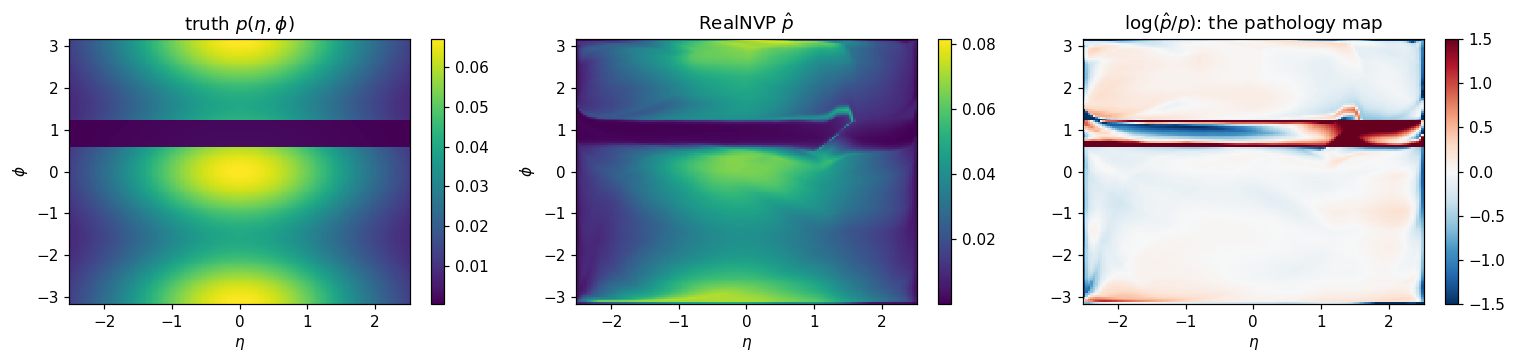

In [3]:
Xt2 = np.stack([test_d["eta"], test_d["phi"]], 1)
lp_m = flow2.log_prob(Xt2)
lp_t = log_p_pos(test_d["eta"], test_d["phi"])
print(f"flow test NLL {-lp_m.mean():.4f} | true NLL {-lp_t.mean():.4f} | KL(p||p_hat) ~ {(lp_t-lp_m).mean():.4f}")

eg = np.linspace(-ETA_MAX, ETA_MAX, 140); fg = np.linspace(-np.pi, np.pi, 140)
E, F = np.meshgrid(eg, fg, indexing="ij")
G = np.stack([E.ravel(), F.ravel()], 1).astype(np.float32)
pm = np.exp(flow2.log_prob(G)).reshape(E.shape)
pt = np.exp(log_p_pos(E, F))
fig, ax = plt.subplots(1, 3, figsize=(14, 3.4))
for a, Mp, ti in zip(ax[:2], [pt, pm], ["truth $p(\\eta,\\phi)$", "RealNVP $\\hat p$"]):
    im = a.pcolormesh(eg, fg, Mp.T); plt.colorbar(im, ax=a); a.set(title=ti, xlabel=r"$\eta$", ylabel=r"$\phi$")
im = ax[2].pcolormesh(eg, fg, (np.log(pm+1e-12) - np.log(pt+1e-12)).T, cmap="RdBu_r", vmin=-1.5, vmax=1.5)
plt.colorbar(im, ax=ax[2]); ax[2].set(title=r"$\log(\hat p/p)$: the pathology map", xlabel=r"$\eta$")
in_sec = (F > SECTOR[0]) & (F < SECTOR[1])
print(f"sector mean density: model {pm[in_sec].mean():.4f} vs truth {pt[in_sec].mean():.4f}"
      f"  (leakage factor ~{pm[in_sec].mean()/pt[in_sec].mean():.1f}x)")
plt.tight_layout()

## 3. Latent-space calibration: the PIT of density estimation

A perfectly trained flow maps the data to its base distribution: push the test events through, and the latents must be $\mathcal{N}(0, I)$ — each marginal Gaussian, no leftover structure. This is the same logic as the PIT ($F(y)$ uniform), in its multivariate flow-native form: **calibration = the model's own transform Gaussianises the data**. Structure left in the latents localises what the flow missed.

**EXERCISE:** colour the latent scatter by whether the event is near the sector edge — where does the leftover structure live?

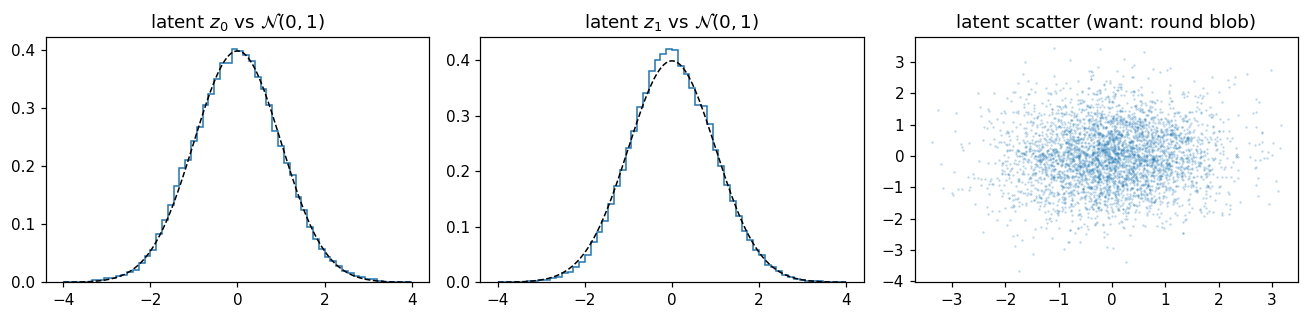

In [4]:
_, zlat = flow2.log_prob(Xt2, return_latent=True)
fig, ax = plt.subplots(1, 3, figsize=(12, 3))
zg = np.linspace(-4, 4, 200)
for i in range(2):
    ax[i].hist(zlat[:, i], bins=60, range=(-4, 4), density=True, histtype="step")
    ax[i].plot(zg, np.exp(-zg**2/2)/np.sqrt(2*np.pi), "k--", lw=1)
    ax[i].set_title(f"latent $z_{i}$ vs $\\mathcal{{N}}(0,1)$")
ax[2].plot(zlat[:4000, 0], zlat[:4000, 1], ".", ms=1, alpha=0.3)
ax[2].set_title("latent scatter (want: round blob)"); plt.tight_layout()

## 4. Epistemic uncertainty *on the density* 

Everything from the uncertainty day applies to $\hat p$ itself: train an ensemble of flows (different seeds), and the member spread is the epistemic error bar on the density. Prediction before you run it: the band is relatively **widest inside the prescaled sector** — few events, so the members disagree there — which is the ensemble telling you which parts of your density estimate to distrust. This single plot is the marriage of the two days, and it is exactly what an ensemble of NPEs does for a posterior in SBI.

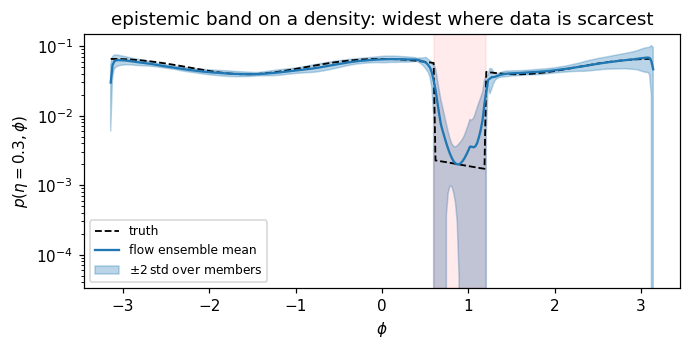

In [5]:
# === SOLUTION ===
flows = [flow2] + [BoundedFlow([-ETA_MAX-0.05, -np.pi-0.05], [ETA_MAX+0.05, np.pi+0.05], seed=s)
                   .fit(X2, verbose=0) for s in range(1, 5)]
phi_line = np.linspace(-np.pi, np.pi, 300).astype(np.float32)
line = np.stack([np.full_like(phi_line, 0.3), phi_line], 1)
P = np.stack([np.exp(fl.log_prob(line)) for fl in flows])
plt.figure(figsize=(7, 3))
plt.plot(phi_line, np.exp(log_p_pos(line[:, 0], phi_line)), "k--", lw=1.2, label="truth")
plt.plot(phi_line, P.mean(0), "C0", label="flow ensemble mean")
plt.fill_between(phi_line, P.mean(0) - 2*P.std(0), P.mean(0) + 2*P.std(0), color="C0", alpha=0.3,
                 label=r"$\pm 2\,$std over members")
plt.axvspan(*SECTOR, color="r", alpha=0.08); plt.yscale("log")
plt.xlabel(r"$\phi$"); plt.ylabel(r"$p(\eta{=}0.3, \phi)$"); plt.legend(fontsize=8)
plt.title("epistemic band on a density: widest where data is scarcest");

## 5. The joint $p(y, \eta, \phi)$ 

Now everything at once: a 3D flow over $(y, \eta, \phi)$. Two payoffs:

1. **Conditional slices for free**: evaluating the joint on a $y$-grid at fixed $(\eta_0,\phi_0)$ and normalising gives $p(y \mid \eta_0, \phi_0)$ — which must reproduce the *analytic mixture* the regression notebook fitted with an MDN head. Same object, reached from the density side. Note it captures the asymmetric tail without ever being told about tails.
2. **This is the SBI move.** Relabel $(\eta,\phi) \to \theta$ and $y \to x$: a network holding a joint or conditional density over data and parameters is a neural likelihood/posterior estimator. Neural Likelihood Estimation trains $p(x\mid\theta)$ exactly like this (with a conditional flow — exercise: refactor `Coupling` to take $(\eta,\phi)$ as conditioning inputs of the net rather than flow dimensions; or use `zuko`/`nflows`).

0 8.13844108581543


2000 3.9607551097869873


4000 3.930002212524414


joint: flow NLL 1.2048 | true NLL 1.1588 | KL ~ 0.0460


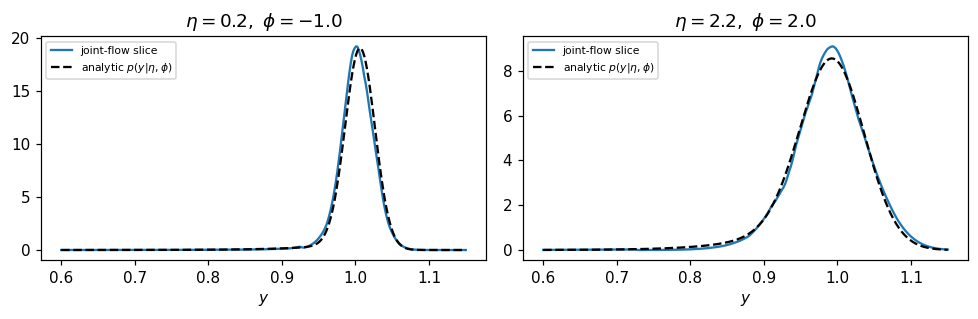

In [6]:
# === SOLUTION ===
X3 = np.stack([train_d["y"], train_d["eta"], train_d["phi"]], 1)
flow3 = BoundedFlow([0.3, -ETA_MAX-0.05, -np.pi-0.05], [1.3, ETA_MAX+0.05, np.pi+0.05], seed=7).fit(X3)

CHECKPTS = [(0.2, -1.0), (2.2, 2.0)]
yg = np.linspace(0.6, 1.15, 300)
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
for a, (e0, f0) in zip(ax, CHECKPTS):
    q = np.stack([yg, np.full_like(yg, e0), np.full_like(yg, f0)], 1).astype(np.float32)
    lp = flow3.log_prob(q)
    p = np.exp(lp - lp.max()); p /= np.trapezoid(p, yg)
    a.plot(yg, p, "C0", label="joint-flow slice")
    a.plot(yg, p_y_cond(yg, e0, f0), "k--", label="analytic $p(y|\\eta,\\phi)$")
    a.set(xlabel="$y$", title=f"$\\eta={e0},\\ \\phi={f0}$"); a.legend(fontsize=7)
plt.tight_layout()

Xt3 = np.stack([test_d["y"], test_d["eta"], test_d["phi"]], 1)
lp_m3 = flow3.log_prob(Xt3)
lp_t3 = np.log(p_y_cond(test_d["y"], test_d["eta"], test_d["phi"]) + 1e-300) + log_p_pos(test_d["eta"], test_d["phi"])
print(f"joint: flow NLL {-lp_m3.mean():.4f} | true NLL {-lp_t3.mean():.4f} | KL ~ {(lp_t3-lp_m3).mean():.4f}")